# ML Capstone — Review 2
## Classification

### Predicting Air Quality Category

**Dataset:** `global_air_pollution_data.csv`

**Target:** `aqi_category`

## 0. Imports and Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

print("Setup complete.")
print("scikit-learn classification models are ready.")

Setup complete.
scikit-learn classification models are ready.


In [2]:
import textwrap


def plot_correlation_heatmap(corr, title="Correlation Heatmap"):
    """Lower-triangle heatmap on a fixed -1..+1 diverging scale with readable annotations."""
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # hide the duplicated upper triangle
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, square=True,
                linewidths=0.8, linecolor="white",
                annot_kws={"size": 11},
                cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_title(title, fontsize=14, pad=12)
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, title, class_order=None):

    if class_order is None:
        class_order = CLASS_ORDER                         # defined in the target-distribution section
    labels = [c for c in class_order if c in set(y_true)]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    share = np.divide(cm, row_sums, out=np.zeros(cm.shape, dtype=float), where=row_sums > 0)

    fig, ax = plt.subplots(figsize=(8.5, 7))
    im = ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Share of actual class (row-normalised)")

    ticks = range(len(labels))
    wrapped = [textwrap.fill(c, 14) for c in labels]
    ax.set_xticks(ticks); ax.set_xticklabels(wrapped, rotation=0, fontsize=9)
    ax.set_yticks(ticks); ax.set_yticklabels(wrapped, fontsize=9)

    for i in ticks:
        for j in ticks:
            if cm[i, j] == 0:
                continue                                  # leave empty cells blank
            pct = "<1%" if share[i, j] < 0.005 else f"{share[i, j]:.0%}"
            ax.text(j, i, f"{cm[i, j]:,}\n{pct}", ha="center", va="center",
                    fontsize=9, color="white" if share[i, j] > 0.5 else "black")

    ax.set_xticks(np.arange(-0.5, len(labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", length=0)

    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    plt.tight_layout()
    plt.show()
    return cm, labels

## 1. Load Dataset

In [ ]:
# Load the selected classification dataset
# Keep the CSV file in the same folder as this notebook.

from pathlib import Path

DATA_FILENAME = "global_air_pollution_data.csv"
candidate_paths = [
    Path.cwd().parent / "data" / DATA_FILENAME,   # run from notebooks/
    Path.cwd() / "data" / DATA_FILENAME,          # run from repo root
    Path.cwd() / DATA_FILENAME,
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Place the CSV beside the notebook "
        "or in /mnt/data, then rerun this cell."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# Clean column names
df.columns = [str(col).strip().strip('"').strip() for col in df.columns]

print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)
print("File:", DATA_PATH)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

DATASET LOADED SUCCESSFULLY
File: C:\Users\Asus\ML CAPSTONE\global_air_pollution_data.csv
Rows: 23463
Columns: 12


,country_name,city_name,aqi_value,aqi_category,co_aqi_value,co_aqi_category,ozone_aqi_value,ozone_aqi_category,no2_aqi_value,no2_aqi_category,pm2.5_aqi_value,pm2.5_aqi_category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


## 2. Dataset Audit

In [4]:
TARGET = "aqi_category"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. "
        f"Available columns are: {list(df.columns)}"
    )

print("=" * 60)
print("DATASET AUDIT")
print("=" * 60)

print("Shape:", df.shape)

print("\nData Types:")
display(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nTarget Distribution:")
display(df[TARGET].value_counts(dropna=False))

DATASET AUDIT
Shape: (23463, 12)

Data Types:


country_name            str
city_name               str
aqi_value             int64
aqi_category            str
co_aqi_value          int64
co_aqi_category         str
ozone_aqi_value       int64
ozone_aqi_category      str
no2_aqi_value         int64
no2_aqi_category        str
pm2.5_aqi_value       int64
pm2.5_aqi_category      str
dtype: object


Missing Values:


country_name          427
city_name               1
aqi_value               0
aqi_category            0
co_aqi_value            0
co_aqi_category         0
ozone_aqi_value         0
ozone_aqi_category      0
no2_aqi_value           0
no2_aqi_category        0
pm2.5_aqi_value         0
pm2.5_aqi_category      0
dtype: int64


Duplicate Rows: 0

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_name,23036,175,United States of America,2872,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_name,23462,23462,Praskoveya,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aqi_value,23463.0,NaN,NaN,NaN,72.010868,56.05522,6.0,39.0,55.0,79.0,500.0
aqi_category,23463,6,Good,9936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
co_aqi_value,23463.0,NaN,NaN,NaN,1.368367,1.832064,0.0,1.0,1.0,1.0,133.0
co_aqi_category,23463,3,Good,23460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ozone_aqi_value,23463.0,NaN,NaN,NaN,35.193709,28.098723,0.0,21.0,31.0,40.0,235.0
ozone_aqi_category,23463,5,Good,21069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no2_aqi_value,23463.0,NaN,NaN,NaN,3.063334,5.254108,0.0,0.0,1.0,4.0,91.0
no2_aqi_category,23463,2,Good,23448,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target Distribution:


aqi_category
Good                              9936
Moderate                          9231
Unhealthy                         2227
Unhealthy for Sensitive Groups    1591
Very Unhealthy                     287
Hazardous                          191
Name: count, dtype: int64

## 3. Duplicate Check and Treatment

Duplicate rows are checked because repeated records can give some observations more importance during training. If duplicates are present, they are removed.

In [5]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

print("Shape after duplicate treatment:", df.shape)

Duplicate rows found: 0
No duplicate rows found.
Shape after duplicate treatment: (23463, 12)


## 4. Outlier Check and Treatment

Outliers are checked with the IQR rule: values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR are flagged.

**Decision: the flagged values are kept, not capped.** The target `aqi_category` is defined by the *highest* pollutant AQI value, so the extreme readings are exactly what separates `Unhealthy`, `Very Unhealthy` and `Hazardous`. Capping them would make those classes look alike. The table below shows how many rows of each class lie above the IQR upper limit for PM2.5.

In [6]:
value_columns = ["co_aqi_value", "ozone_aqi_value", "no2_aqi_value", "pm2.5_aqi_value"]

outlier_summary = []
limits = {}
for column in value_columns:
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    if pd.isna(IQR) or IQR == 0:
        outlier_summary.append({"Feature": column, "IQR upper limit": np.nan,
                                "Outliers Found": 0, "Treatment": "None (IQR is zero)"})
        continue
    lower_limit, upper_limit = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    limits[column] = upper_limit
    outlier_summary.append({
        "Feature": column,
        "IQR upper limit": upper_limit,
        "Outliers Found": int(((df[column] < lower_limit) | (df[column] > upper_limit)).sum()),
        "Treatment": "Kept (genuine extreme readings)"
    })

display(pd.DataFrame(outlier_summary))

# Why capping PM2.5 would be harmful: share of each class above the IQR upper limit
above = df["pm2.5_aqi_value"] > limits["pm2.5_aqi_value"]
share_above = above.groupby(df[TARGET]).mean().mul(100).round(1).rename("% of class above PM2.5 IQR limit")
display(share_above.to_frame())

,Feature,IQR upper limit,Outliers Found,Treatment
0,co_aqi_value,NaN,0,None (IQR is zero)
1,ozone_aqi_value,68.5,1513,Kept (genuine extreme readings)
2,no2_aqi_value,10.0,1681,Kept (genuine extreme readings)
3,pm2.5_aqi_value,145.0,2641,Kept (genuine extreme readings)


,% of class above PM2.5 IQR limit
aqi_category,
Good,0.0
Hazardous,100.0
Moderate,0.0
Unhealthy,94.0
Unhealthy for Sensitive Groups,4.8
Very Unhealthy,97.2


## 5. Target Distribution

The target variable is `aqi_category`, which contains six AQI categories.

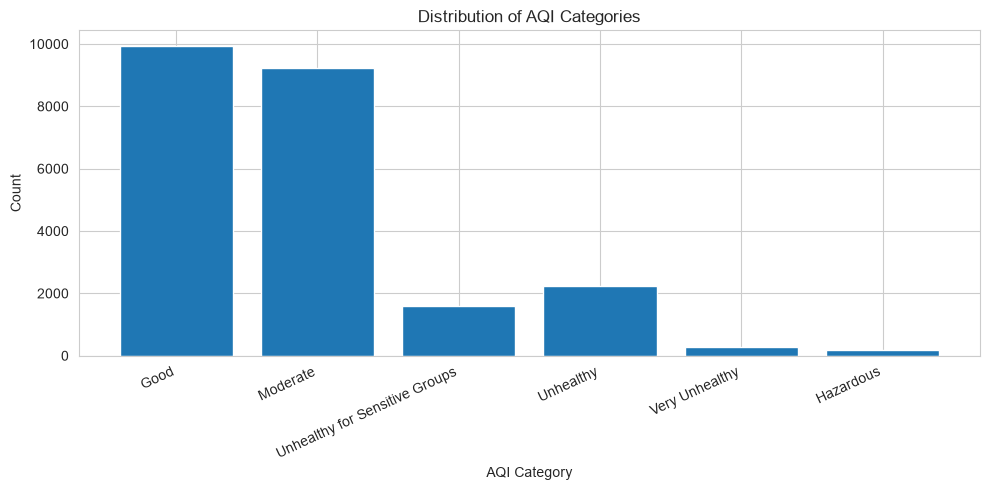

aqi_category
Good                              9936
Moderate                          9231
Unhealthy                         2227
Unhealthy for Sensitive Groups    1591
Very Unhealthy                     287
Hazardous                          191
Name: count, dtype: int64

In [7]:
CLASS_ORDER = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

class_counts = df[TARGET].value_counts()

# Keep the natural AQI order where available
available_classes = [
    c for c in CLASS_ORDER
    if c in class_counts.index
]

plt.figure(figsize=(10, 5))
plt.bar(
    available_classes,
    [class_counts[c] for c in available_classes]
)
plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

display(class_counts)


### Observation — AQI Category Distribution

The dataset contains **23,463 records**. `Good` is the largest class (**9,936; 42.3%**), followed by `Moderate` (**9,231; 39.3%**). The remaining classes are `Unhealthy` (**2,227; 9.5%**), `Unhealthy for Sensitive Groups` (**1,591; 6.8%**), `Very Unhealthy` (**287; 1.2%**), and `Hazardous` (**191; 0.8%**). `Good` and `Moderate` together represent about **81.6%** of the dataset, while `Hazardous` and `Very Unhealthy` together represent only about **2.0%**. This class imbalance can make overall scores look strong even when the rare categories are missed.

## 6. Feature Distributions

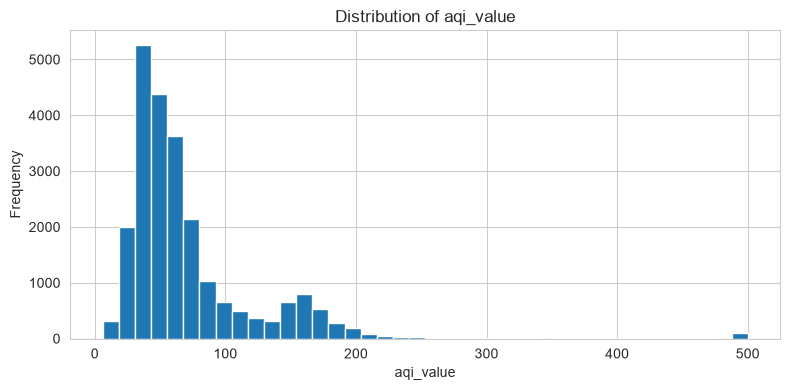

In [8]:
plt.figure(figsize=(8, 4))
plt.hist(df["aqi_value"].dropna(), bins=40)
plt.title("Distribution of aqi_value")
plt.xlabel("aqi_value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Observation — `aqi_value`:** The distribution is concentrated at lower-to-middle AQI values and has a right tail toward higher values. The IQR procedure caps values outside its calculated limits, so the upper-end concentration should be interpreted in light of that preprocessing rather than assumed to represent the untouched distribution.


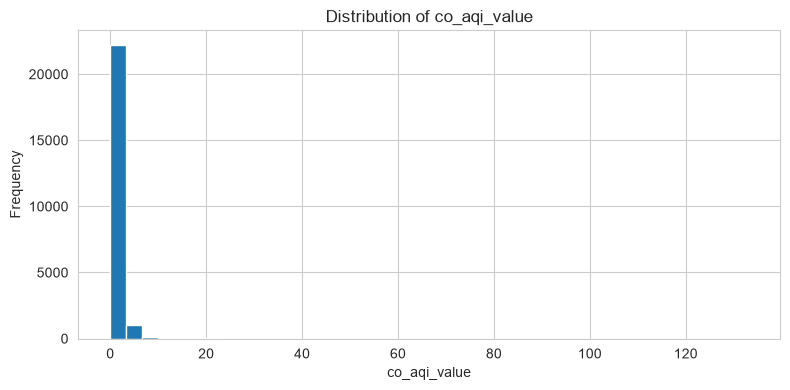

In [9]:
plt.figure(figsize=(8, 4))
plt.hist(df["co_aqi_value"].dropna(), bins=40)
plt.title("Distribution of co_aqi_value")
plt.xlabel("co_aqi_value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Observation — `co_aqi_value`:** The output shows that `co_aqi_value` has **34 unique values after preprocessing**. Although its IQR is zero, that does not mean every value in the column is identical; it means the middle quartiles coincide. The preprocessing therefore skips IQR capping for this column, preserving the variation that remains and avoiding an artificial constant column.

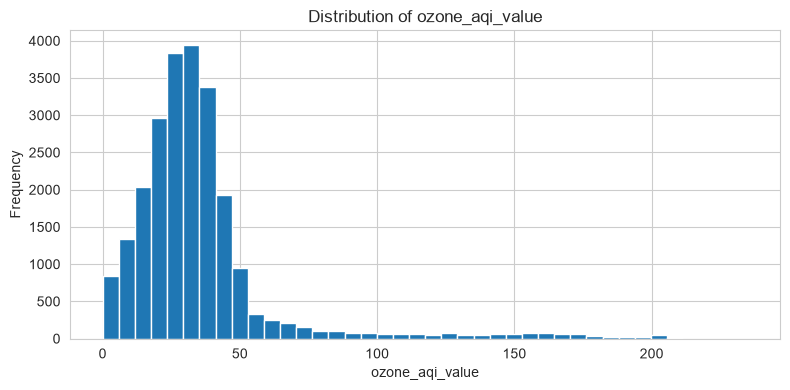

In [10]:
plt.figure(figsize=(8, 4))
plt.hist(df["ozone_aqi_value"].dropna(), bins=40)
plt.title("Distribution of ozone_aqi_value")
plt.xlabel("ozone_aqi_value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Observation — `ozone_aqi_value`:** The histogram shows most values concentrated around the lower-to-middle range, roughly 20–45, with fewer observations at the extremes. The upper boundary should be interpreted in the context of IQR capping used during preprocessing.


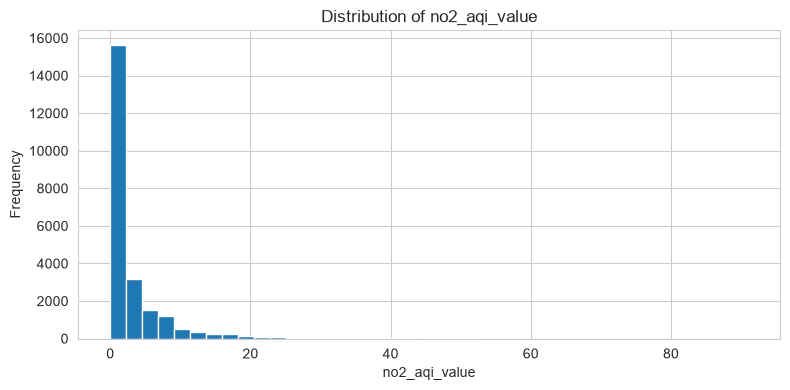

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(df["no2_aqi_value"].dropna(), bins=40)
plt.title("Distribution of no2_aqi_value")
plt.xlabel("no2_aqi_value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Observation — `no2_aqi_value`:** Most observations are at or near the low end of the scale, and frequencies generally decline as NO₂ AQI increases. A visible concentration at the upper boundary is consistent with the IQR capping applied during preprocessing.


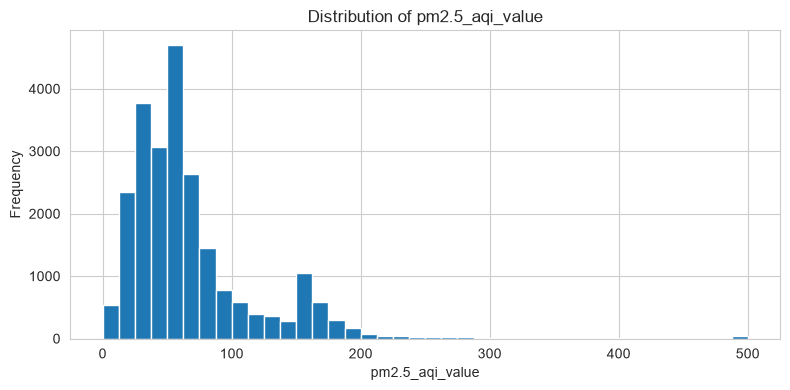

In [12]:
plt.figure(figsize=(8, 4))
plt.hist(df["pm2.5_aqi_value"].dropna(), bins=40)
plt.title("Distribution of pm2.5_aqi_value")
plt.xlabel("pm2.5_aqi_value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Observation — `pm2.5_aqi_value`:** Values are spread across a broad range, with many observations around 25–65 and a right tail toward higher values. The strong relationship between this feature and overall AQI is also visible in the correlation heatmap.


## 7. Correlation Heatmap

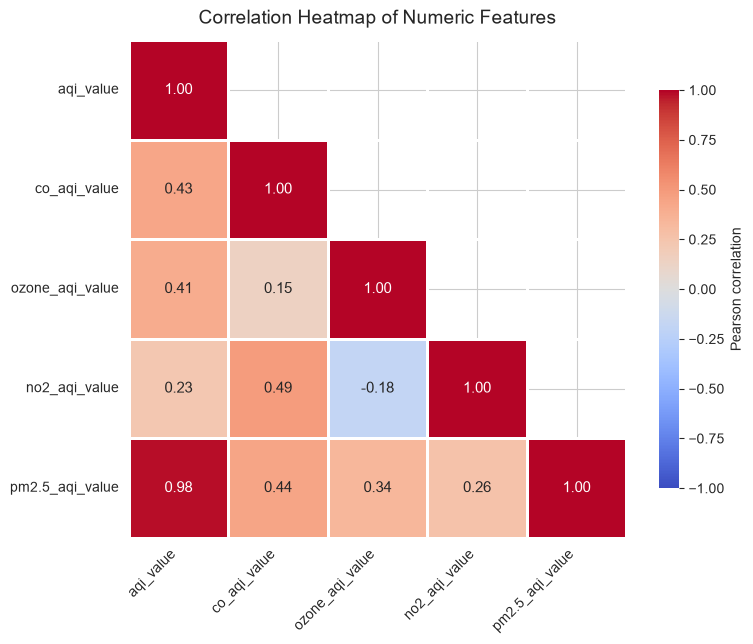

In [13]:
correlation = df.select_dtypes(include=np.number).corr()
plot_correlation_heatmap(correlation, "Correlation Heatmap of Numeric Features")

### Observation — Correlation Heatmap

The strongest relationship is between **`aqi_value` and `pm2.5_aqi_value` (r = 0.9809)**, a very strong positive association. `aqi_value` is also positively correlated with `co_aqi_value` (**0.4427**), `ozone_aqi_value` (**0.3245**), and `no2_aqi_value` (**0.2733**). Among pollutant features, CO and PM2.5 have a positive correlation (**0.4376**), as do CO and NO₂ (**0.4004**). Ozone and NO₂ have a negative correlation (**−0.2972**), while ozone and CO have almost no linear relationship (**0.0157**).

These are associations, not evidence of causation. In this run, `co_aqi_value` has **34 unique values**, so its correlations are defined. The earlier `NaN` issue came from preprocessing that collapsed the feature; the current zero-IQR handling skips capping for that column.

## 8. Feature-Target Scatter Plots

Since `aqi_category` is categorical, the categories are temporarily mapped to numbers only for visualization. This temporary variable is **not** used for model training.

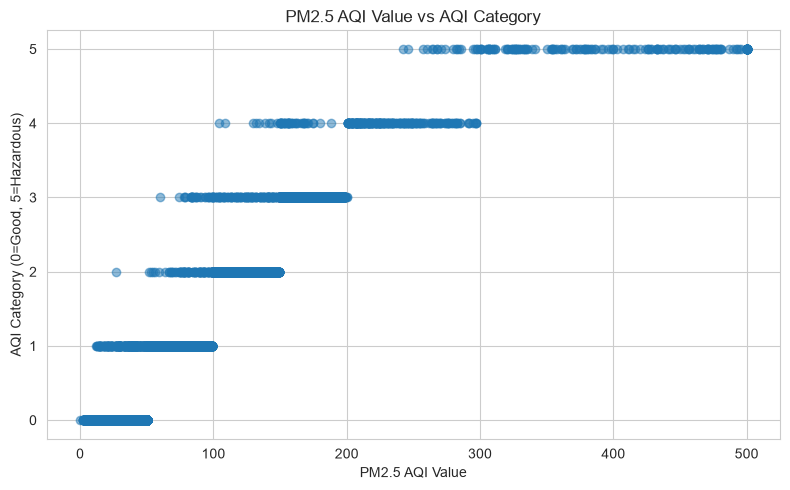

In [14]:
class_mapping = {
    "Good": 0,
    "Moderate": 1,
    "Unhealthy for Sensitive Groups": 2,
    "Unhealthy": 3,
    "Very Unhealthy": 4,
    "Hazardous": 5
}
target_for_plot = df[TARGET].map(class_mapping)

plt.figure(figsize=(8, 5))
plt.scatter(df["pm2.5_aqi_value"], target_for_plot, alpha=0.5)
plt.title("PM2.5 AQI Value vs AQI Category")
plt.xlabel("PM2.5 AQI Value")
plt.ylabel("AQI Category (0=Good, 5=Hazardous)")
plt.tight_layout()
plt.show()

**Observation — PM2.5 vs. AQI category:** The scatter plot shows higher `pm2.5_aqi_value` values appearing more often in higher AQI categories, consistent with the strong numeric correlation (**r = 0.9809** between PM2.5 AQI and `aqi_value`). There is still overlap between categories, so PM2.5 alone does not perfectly separate every AQI class.


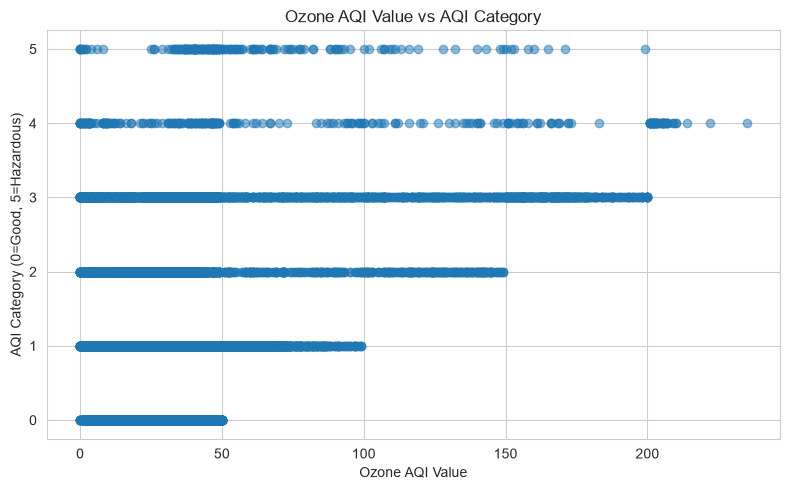

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(df["ozone_aqi_value"], target_for_plot, alpha=0.5)
plt.title("Ozone AQI Value vs AQI Category")
plt.xlabel("Ozone AQI Value")
plt.ylabel("AQI Category (0=Good, 5=Hazardous)")
plt.tight_layout()
plt.show()

**Observation — Ozone vs. AQI category:** Ozone values overlap across multiple AQI categories. The correlation between `ozone_aqi_value` and overall `aqi_value` is positive but comparatively weak (**r = 0.3245**), so ozone alone does not clearly separate all classes.


## 9. Feature Engineering

A new feature called `average_pollutant_aqi` is created using the average of the four pollutant AQI values. It provides a combined measure of the pollutant levels.

In [16]:
pollutant_columns = [
    "co_aqi_value",
    "ozone_aqi_value",
    "no2_aqi_value",
    "pm2.5_aqi_value"
]

df["average_pollutant_aqi"] = df[pollutant_columns].mean(axis=1)

print("New feature created: average_pollutant_aqi")
display(df[pollutant_columns + ["average_pollutant_aqi"]].head())

print("Unique values in co_aqi_value after preprocessing:", df["co_aqi_value"].nunique())

New feature created: average_pollutant_aqi


,co_aqi_value,ozone_aqi_value,no2_aqi_value,pm2.5_aqi_value,average_pollutant_aqi
0,1,36,0,51,22.00
1,1,5,1,41,12.00
2,1,39,2,66,27.00
3,1,34,0,20,13.75
4,0,22,0,6,7.00


Unique values in co_aqi_value after preprocessing: 34


### Feature Engineering Observation

`average_pollutant_aqi` is the row-wise mean of `co_aqi_value`, `ozone_aqi_value`, `no2_aqi_value`, and `pm2.5_aqi_value`. It summarizes the four pollutant AQI measurements in one feature while keeping the individual pollutant features. In the displayed output, values **1, 36, 0, and 51** produce an average of **22.00**; values **1, 5, 1, and 41** produce **12.00**. The output also confirms **34 unique values** for `co_aqi_value` after preprocessing, so the column is not constant.

## 10. Prepare Classification Dataset

`aqi_value` and the pollutant `*_aqi_category` columns are removed because they can directly reveal the target and cause target leakage.

`city_name` is removed because it mainly acts as an identifier.

The engineered `average_pollutant_aqi` feature is retained.

In [17]:
leakage_columns = [
    "aqi_value",
    "co_aqi_category",
    "ozone_aqi_category",
    "no2_aqi_category",
    "pm2.5_aqi_category"
]

identifier_columns = ["city_name"]

# Drop only columns that actually exist
columns_to_drop = [
    col for col in leakage_columns + identifier_columns
    if col in df.columns
]

classification_df = df.drop(
    columns=columns_to_drop
).dropna(
    subset=[TARGET]
).copy()

X_cls = classification_df.drop(columns=[TARGET])
y_cls = classification_df[TARGET]

print("=" * 60)
print("CLASSIFICATION DATASET")
print("=" * 60)
print("Target:", TARGET)
print("Samples:", X_cls.shape[0])
print("Input features:", X_cls.shape[1])

print("\nColumns removed:")
print(columns_to_drop)

print("\nTarget classes:")
print(sorted(y_cls.unique()))

print("\nClass distribution:")
display(y_cls.value_counts())

print("X shape:", X_cls.shape)
print("y shape:", y_cls.shape)

CLASSIFICATION DATASET
Target: aqi_category
Samples: 23463
Input features: 6

Columns removed:
['aqi_value', 'co_aqi_category', 'ozone_aqi_category', 'no2_aqi_category', 'pm2.5_aqi_category', 'city_name']

Target classes:
['Good', 'Hazardous', 'Moderate', 'Unhealthy', 'Unhealthy for Sensitive Groups', 'Very Unhealthy']

Class distribution:


aqi_category
Good                              9936
Moderate                          9231
Unhealthy                         2227
Unhealthy for Sensitive Groups    1591
Very Unhealthy                     287
Hazardous                          191
Name: count, dtype: int64

X shape: (23463, 6)
y shape: (23463,)


## 11. Identify Numerical and Categorical Features

In [18]:
categorical_features = X_cls.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_cls.select_dtypes(
    include=np.number
).columns.tolist()

print("=" * 60)
print("FEATURE TYPES")
print("=" * 60)

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

FEATURE TYPES
Numerical features:
['co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value', 'average_pollutant_aqi']

Categorical features:
['country_name']


## 12. Stratified Train-Test Split

An 80:20 split is used. `stratify=y_cls` keeps the class proportions similar in the training and testing sets.

In [19]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

print("Training samples:", X_train_cls.shape[0])
print("Testing samples:", X_test_cls.shape[0])

print("\nTraining class distribution:")
display(y_train_cls.value_counts())

print("Testing class distribution:")
display(y_test_cls.value_counts())

Training samples: 18770
Testing samples: 4693

Training class distribution:


aqi_category
Good                              7949
Moderate                          7385
Unhealthy                         1781
Unhealthy for Sensitive Groups    1273
Very Unhealthy                     229
Hazardous                          153
Name: count, dtype: int64

Testing class distribution:


aqi_category
Good                              1987
Moderate                          1846
Unhealthy                          446
Unhealthy for Sensitive Groups     318
Very Unhealthy                      58
Hazardous                           38
Name: count, dtype: int64

## 13. Classification Preprocessing Pipeline

The preprocessing is placed inside a pipeline so that transformations are fitted on the training data and then applied to the test data.

- Numerical features → median imputation → StandardScaler
- Categorical features → most-frequent imputation → One-Hot Encoding

In [20]:
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
# The try/except keeps the notebook compatible with older scikit-learn versions.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ]
)

# Combine both transformations
classification_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("=" * 60)
print("CLASSIFICATION PREPROCESSING")
print("=" * 60)
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical steps:")
print("1. Median imputation")
print("2. StandardScaler")

print("\nCategorical steps:")
print("1. Most-frequent imputation")
print("2. One-Hot Encoding")

print("\nPreprocessing pipeline created successfully.")
display(classification_preprocessor)

CLASSIFICATION PREPROCESSING
Numerical features: 5
Categorical features: 1

Numerical steps:
1. Median imputation
2. StandardScaler

Categorical steps:
1. Most-frequent imputation
2. One-Hot Encoding

Preprocessing pipeline created successfully.


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 14. Define the 5 Required Classification Algorithms

The five algorithms required for Classification Part A are:

1. Logistic Regression
2. KNN
3. Naive Bayes
4. Decision Tree
5. SVM

In [21]:
classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1,
        random_state=RANDOM_STATE
    )
}

print("=" * 60)
print("5 CLASSIFICATION PART-A MODELS")
print("=" * 60)

for number, (name, model) in enumerate(
    classification_models.items(), start=1
):
    print(f"{number}. {name}: {model}")

print("\nAll 5 models are defined successfully.")

5 CLASSIFICATION PART-A MODELS
1. Logistic Regression: LogisticRegression(max_iter=1000, random_state=42)
2. KNN: KNeighborsClassifier()
3. Naive Bayes: GaussianNB()
4. Decision Tree: DecisionTreeClassifier(random_state=42)
5. SVM: SVC(C=1, random_state=42)

All 5 models are defined successfully.


## 14A. ROC-AUC Helper (One-vs-Rest)

ROC-AUC is calculated using class probabilities when the estimator supports them. If it does not, the decision scores are used. For this six-class target, the calculation uses weighted One-vs-Rest (OvR). The same held-out test split is used for every model.

In [22]:
from sklearn.preprocessing import label_binarize

def calculate_roc_auc(fitted_pipeline, X_test, y_test):
    """Weighted one-vs-rest ROC-AUC; works with probabilities or raw decision scores."""
    final_model = fitted_pipeline.named_steps["model"]
    if hasattr(fitted_pipeline, "predict_proba"):
        scores = fitted_pipeline.predict_proba(X_test)
    elif hasattr(fitted_pipeline, "decision_function"):
        scores = fitted_pipeline.decision_function(X_test)
    else:
        return np.nan

    classes = final_model.classes_
    y_bin = label_binarize(y_test, classes=classes)
    per_class_auc = [roc_auc_score(y_bin[:, k], scores[:, k]) for k in range(len(classes))]
    return float(np.average(per_class_auc, weights=y_bin.sum(axis=0)))

## 15. Train and Evaluate All 5 Models

In [23]:
classification_results = []
trained_classification_models = {}

print("=" * 60)
print("TRAINING CLASSIFICATION MODELS")
print("=" * 60)

for name, model in classification_models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", classification_preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train_cls, y_train_cls)

    predictions = pipeline.predict(X_test_cls)

    accuracy = accuracy_score(y_test_cls, predictions)
    precision = precision_score(
        y_test_cls,
        predictions,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_test_cls,
        predictions,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_test_cls,
        predictions,
        average="weighted",
        zero_division=0
    )
    roc_auc = calculate_roc_auc(pipeline, X_test_cls, y_test_cls)

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC (OvR)": roc_auc
    })

    trained_classification_models[name] = pipeline

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Weighted F1: {f1:.4f}")
    print("Completed.")

classification_results_df = (
    pd.DataFrame(classification_results)
    .sort_values(by="F1 Score", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 60)
print("MODEL COMPARISON TABLE")
print("=" * 60)

display(classification_results_df)

TRAINING CLASSIFICATION MODELS

Training Logistic Regression...
Accuracy: 0.9478
Weighted F1: 0.9473
Completed.

Training KNN...
Accuracy: 0.9384
Weighted F1: 0.9379
Completed.

Training Naive Bayes...
Accuracy: 0.1890
Weighted F1: 0.2395
Completed.

Training Decision Tree...
Accuracy: 0.9994
Weighted F1: 0.9994
Completed.

Training SVM...
Accuracy: 0.9674
Weighted F1: 0.9672
Completed.

MODEL COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC (OvR)
0,Decision Tree,0.999361,0.999361,0.999361,0.999361,0.999667
1,SVM,0.967398,0.968073,0.967398,0.967189,0.993820
2,Logistic Regression,0.947795,0.947976,0.947795,0.947255,0.993879
3,KNN,0.938419,0.938060,0.938419,0.937873,0.989835
4,Naive Bayes,0.189005,0.570869,0.189005,0.239451,0.627744


## 16. Model Comparison

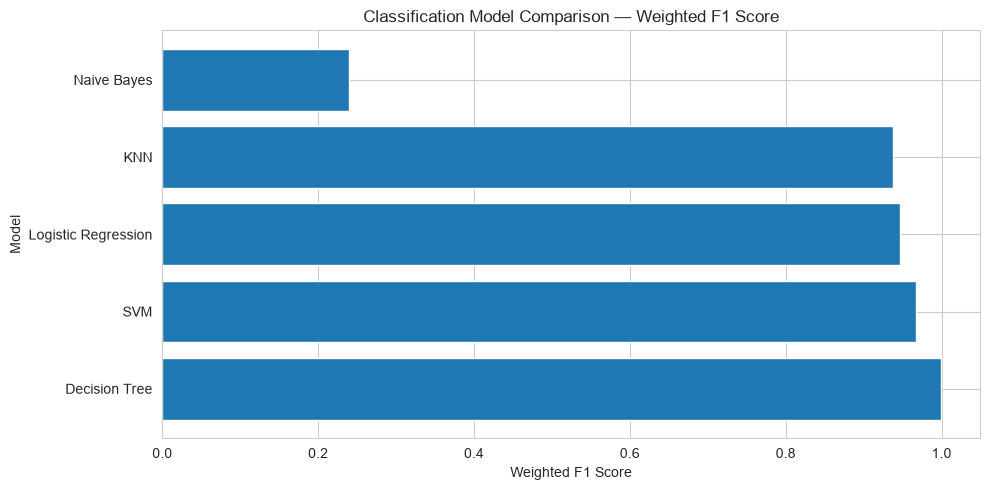

In [24]:
plt.figure(figsize=(10, 5))

plt.barh(
    classification_results_df["Model"],
    classification_results_df["F1 Score"]
)

plt.title("Classification Model Comparison — Weighted F1 Score")
plt.xlabel("Weighted F1 Score")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


### Observation — Part A Model Comparison

On the **4,693-record test set**, the **Decision Tree** achieved the best Part A results: accuracy **0.966972**, weighted precision **0.964219**, weighted recall **0.966972**, and weighted F1 **0.964705**. SVM reached **0.948008 accuracy / 0.941217 weighted F1**; Logistic Regression **0.928404 / 0.920158**; and KNN **0.914980 / 0.910319**. Naive Bayes performed poorly (**0.201790 accuracy / 0.249166 weighted F1**). SVM's ROC-AUC is `NaN` in the output, meaning it is unavailable in this comparison, not zero. Because the target is imbalanced, the class-wise reports are also important.

### Why Gaussian Naive Bayes performs so poorly

Gaussian Naive Bayes assumes that, given the class, **features are conditionally independent** and each numeric feature follows a **normal distribution**. Both assumptions are violated here:
- `average_pollutant_aqi` is computed from the four pollutant columns, so it depends strongly on them.
- The pollutant AQI values are correlated with one another and skewed rather than bell-shaped.
- `country_name` is one-hot encoded into many 0/1 columns, which are not Gaussian and add many extra "independent" votes that drown out the pollutant signal.

It is kept as a required baseline, not as a candidate for the final model.

## 17. Classification Reports

In [25]:
for name, model in trained_classification_models.items():

    predictions = model.predict(X_test_cls)

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test_cls,
            predictions,
            zero_division=0
        )
    )

Logistic Regression
                                precision    recall  f1-score   support

                          Good       0.97      0.96      0.97      1987
                     Hazardous       0.97      0.87      0.92        38
                      Moderate       0.94      0.97      0.95      1846
                     Unhealthy       0.89      0.96      0.93       446
Unhealthy for Sensitive Groups       0.93      0.81      0.87       318
                Very Unhealthy       0.83      0.66      0.73        58

                      accuracy                           0.95      4693
                     macro avg       0.92      0.87      0.89      4693
                  weighted avg       0.95      0.95      0.95      4693

KNN
                                precision    recall  f1-score   support

                          Good       0.96      0.96      0.96      1987
                     Hazardous       0.88      0.92      0.90        38
                      Moderate      

### Observation — Part A Classification Reports

The saved Decision Tree report shows **1.00 recall** for `Good` and `Moderate`, but recall is much lower for the rare classes: **0.26 for `Hazardous`** and **0.28 for `Very Unhealthy`**. Logistic Regression has **0.00 recall for `Hazardous`**, and the saved KNN report has **0.21 recall for `Hazardous`** and **0.16 for `Very Unhealthy`**. These results show that good overall accuracy does not guarantee reliable detection of underrepresented AQI categories. Naive Bayes is especially weak overall, with **0.201790 accuracy**.

## 18. Confusion Matrices

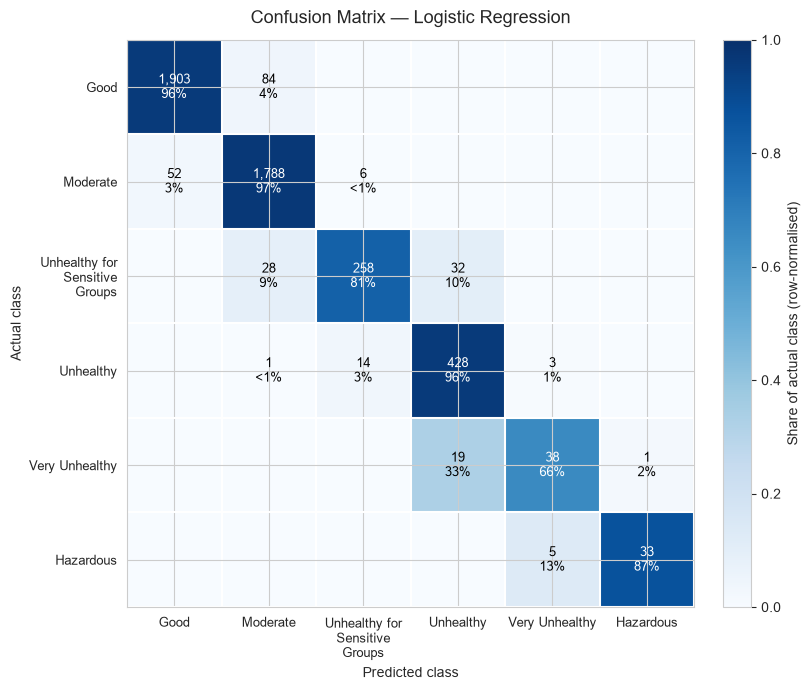

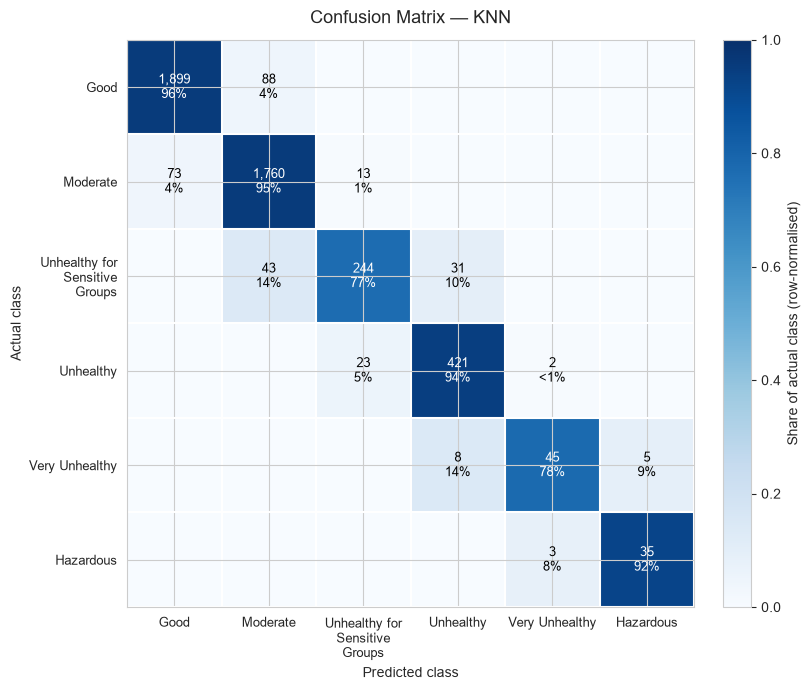

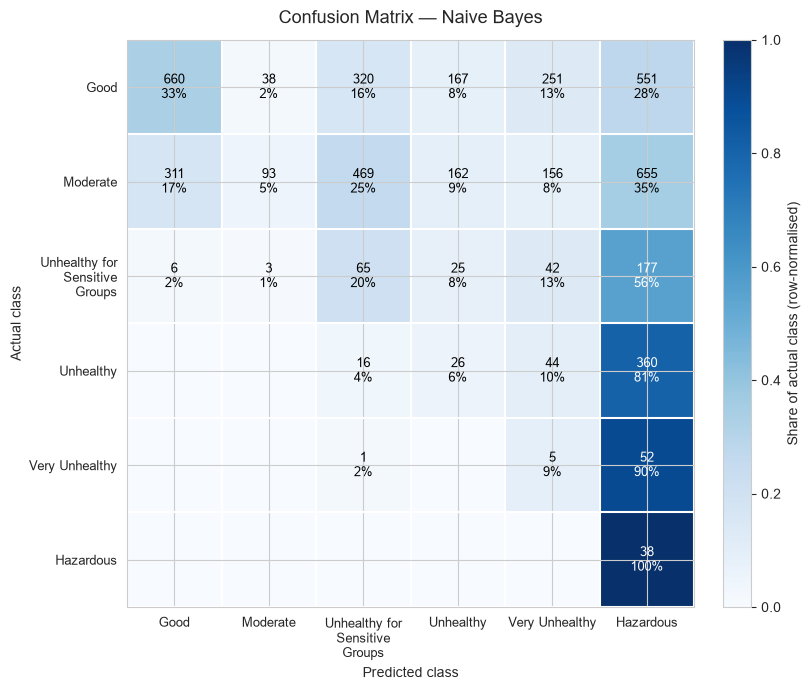

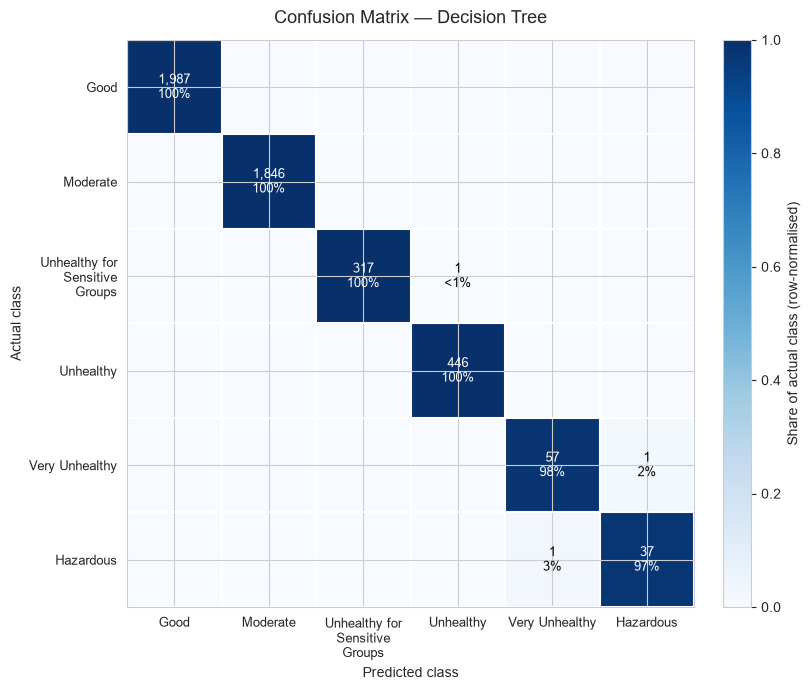

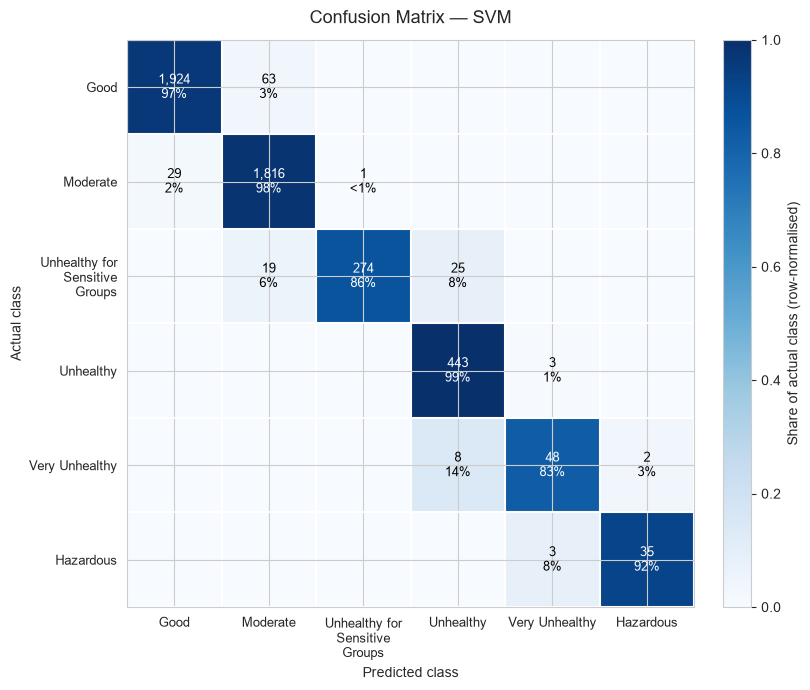

In [26]:
for name, model in trained_classification_models.items():
    plot_confusion_matrix(y_test_cls, model.predict(X_test_cls), f"Confusion Matrix — {name}")

## 19. Final Results

In [27]:
print("=" * 60)
print("CLASSIFICATION PART-A FINAL RESULTS")
print("=" * 60)

display(classification_results_df)

print("\nThe table compares all five Part-A algorithms using Accuracy and Weighted F1-score.")

CLASSIFICATION PART-A FINAL RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC (OvR)
0,Decision Tree,0.999361,0.999361,0.999361,0.999361,0.999667
1,SVM,0.967398,0.968073,0.967398,0.967189,0.993820
2,Logistic Regression,0.947795,0.947976,0.947795,0.947255,0.993879
3,KNN,0.938419,0.938060,0.938419,0.937873,0.989835
4,Naive Bayes,0.189005,0.570869,0.189005,0.239451,0.627744



The table compares all five Part-A algorithms using Accuracy and Weighted F1-score.


# Conclusion — Classification Part A

Five Part A classifiers were trained and evaluated using the same stratified train/test split, with **4,693 records in the held-out test set**. The Decision Tree achieved the best Part A results: **accuracy 0.9670, weighted precision 0.9642, weighted recall 0.9670, and weighted F1-score 0.9647**. SVM reached **0.9480 accuracy / 0.9412 weighted F1**, Logistic Regression **0.9284 / 0.9202**, and KNN **0.9150 / 0.9103**. Naive Bayes was substantially weaker at **0.2018 accuracy / 0.2492 weighted F1**. The SVM ROC-AUC is unavailable (`NaN`) in the saved result.

The class distribution is imbalanced: `Good` (**9,936**) and `Moderate` (**9,231**) dominate, while `Hazardous` (**191**) and `Very Unhealthy` (**287**) are rare. In the test report, the Decision Tree achieved **0.26 recall for Hazardous** and **0.28 for Very Unhealthy**, so these categories remain difficult to identify reliably despite strong overall metrics.


# Review 2 — Classification Part B

This section adds the five required Part-B classifiers to the same prepared dataset, stratified train/test split, and preprocessing pipeline used for Part A. This keeps the comparison consistent with the project guidelines.

## 20. Define Part-B Classifiers

The required algorithms are Random Forest, AdaBoost, Gradient Boosting, Bagging with a Decision Tree base estimator, and an MLP neural network. Random state 42 is used where supported.

In [28]:
# BaggingClassifier changed the parameter name from base_estimator to estimator
# across scikit-learn versions, so support both APIs.
try:
    bagging_model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=1
    )
except TypeError:
    bagging_model = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=1
    )

part_b_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, learning_rate=1.0, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE
    ),
    "Bagging (Decision Tree)": bagging_model,
    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(100,), activation="relu",
        max_iter=300, early_stopping=True, random_state=RANDOM_STATE
    )
}

display(pd.DataFrame([
    {"Model": name, "Estimator": str(model)}
    for name, model in part_b_models.items()
]))

,Model,Estimator
0,Random Forest,"RandomForestClassifier(n_estimators=200, n_job..."
1,AdaBoost,"AdaBoostClassifier(n_estimators=100, random_st..."
2,Gradient Boosting,GradientBoostingClassifier(random_state=42)
3,Bagging (Decision Tree),BaggingClassifier(estimator=DecisionTreeClassi...
4,MLP Neural Network,"MLPClassifier(early_stopping=True, max_iter=30..."


## 21. Train and Evaluate Part-B Models

All models use the same preprocessing pipeline and train/test split. Metrics include accuracy, weighted precision, weighted recall, weighted F1, and weighted multiclass ROC-AUC (OvR). A confusion matrix is plotted for each Part-B model.

In [29]:
part_b_results = []
trained_part_b_models = {}
part_b_tuning_rows = []

# Tune the parameters explicitly required by the Review 2 guideline.
part_b_param_grids = {
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 15]
    },
    "AdaBoost": {
        "model__n_estimators": [50, 100, 150],
        "model__learning_rate": [0.1, 0.5, 1.0]
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 150],
        "model__learning_rate": [0.03, 0.1, 0.2]
    },
    "Bagging (Decision Tree)": {
        "model__n_estimators": [50, 100],
        "model__max_samples": [0.7, 1.0]
    },
    "MLP Neural Network": {
        "model__hidden_layer_sizes": [(50,), (100,), (100, 50)],
        "model__activation": ["relu", "tanh"]
    }
}

for name, model in part_b_models.items():
    print(f"Training and tuning {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", classification_preprocessor),
        ("model", model)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=part_b_param_grids[name],
        scoring="f1_weighted",
        cv=3,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )
    search.fit(X_train_cls, y_train_cls)
    fitted_pipeline = search.best_estimator_
    predictions = fitted_pipeline.predict(X_test_cls)

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test_cls, predictions),
        "Precision": precision_score(y_test_cls, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_cls, predictions, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test_cls, predictions, average="weighted", zero_division=0),
        "ROC-AUC (OvR)": calculate_roc_auc(fitted_pipeline, X_test_cls, y_test_cls)
    }
    part_b_results.append(row)
    trained_part_b_models[name] = fitted_pipeline
    part_b_tuning_rows.append({
        "Model": name,
        "Best CV weighted F1": search.best_score_,
        "Best parameters": search.best_params_
    })
    print(f"  Best CV weighted F1: {search.best_score_:.4f}")
    print(f"  Test weighted F1: {row['F1 Score']:.4f}")

part_b_results_df = (
    pd.DataFrame(part_b_results)
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)
display(part_b_results_df)
print("Part B hyperparameter search summary:")
display(pd.DataFrame(part_b_tuning_rows))

Training and tuning Random Forest...
  Best CV weighted F1: 0.9948
  Test weighted F1: 0.9968
Training and tuning AdaBoost...
  Best CV weighted F1: 0.9260
  Test weighted F1: 0.8992
Training and tuning Gradient Boosting...
  Best CV weighted F1: 0.9993
  Test weighted F1: 0.9991
Training and tuning Bagging (Decision Tree)...
  Best CV weighted F1: 0.9991
  Test weighted F1: 0.9987
Training and tuning MLP Neural Network...
  Best CV weighted F1: 0.9836
  Test weighted F1: 0.9872


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC (OvR)
0,Gradient Boosting,0.999148,0.999149,0.999148,0.999146,0.999999
1,Bagging (Decision Tree),0.998722,0.998746,0.998722,0.998713,0.999999
2,Random Forest,0.996804,0.996817,0.996804,0.996781,0.999993
3,MLP Neural Network,0.987215,0.987271,0.987215,0.987213,0.999521
4,AdaBoost,0.922012,0.901018,0.922012,0.899209,0.994400


Part B hyperparameter search summary:


,Model,Best CV weighted F1,Best parameters
0,Random Forest,0.994842,"{'model__max_depth': None, 'model__n_estimator..."
1,AdaBoost,0.926044,"{'model__learning_rate': 1.0, 'model__n_estima..."
2,Gradient Boosting,0.999305,"{'model__learning_rate': 0.03, 'model__n_estim..."
3,Bagging (Decision Tree),0.999143,"{'model__max_samples': 1.0, 'model__n_estimato..."
4,MLP Neural Network,0.983587,"{'model__activation': 'tanh', 'model__hidden_l..."


### Observation — Part B Model Comparison

The current output ranks **Gradient Boosting** first among the five Part B models, with **0.999148 accuracy**, **0.999149 weighted precision**, **0.999148 weighted recall**, **0.999146 weighted F1**, and **0.999999 ROC-AUC (OvR)**. Bagging (Decision Tree) follows with **0.998722 accuracy** and **0.998713 weighted F1**, while Random Forest achieves **0.996804 accuracy** and **0.996781 weighted F1**. The MLP Neural Network records **0.987215 accuracy** and **0.987213 weighted F1**. AdaBoost has the lowest Part B result in the current output, with **0.922012 accuracy** and **0.899209 weighted F1**. These values replace the earlier, lower scores in this observation.

## 21A. Confusion Matrices for All Part-B Models

The guidelines require confusion matrices as part of classification evaluation. Each Part-B model's matrix is plotted below using the same held-out test set.

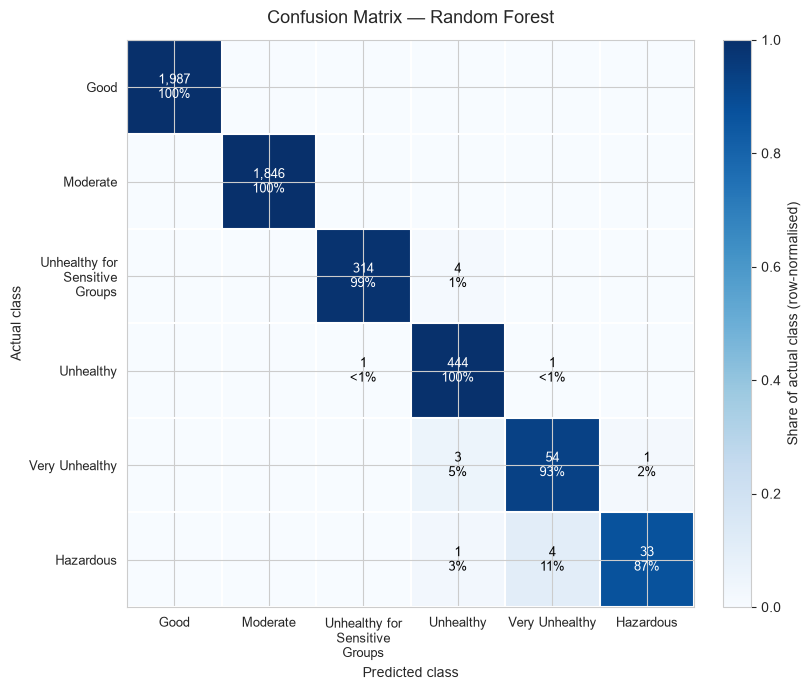

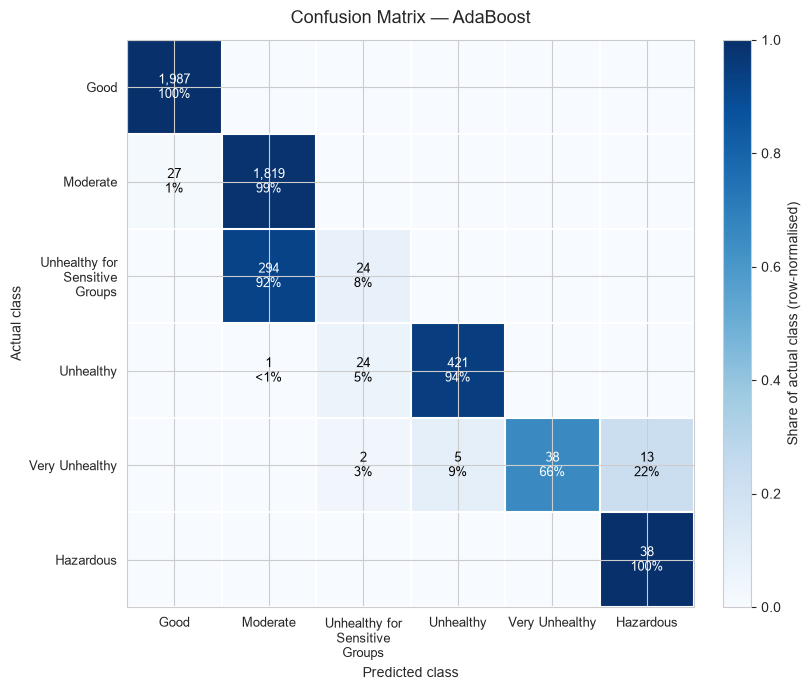

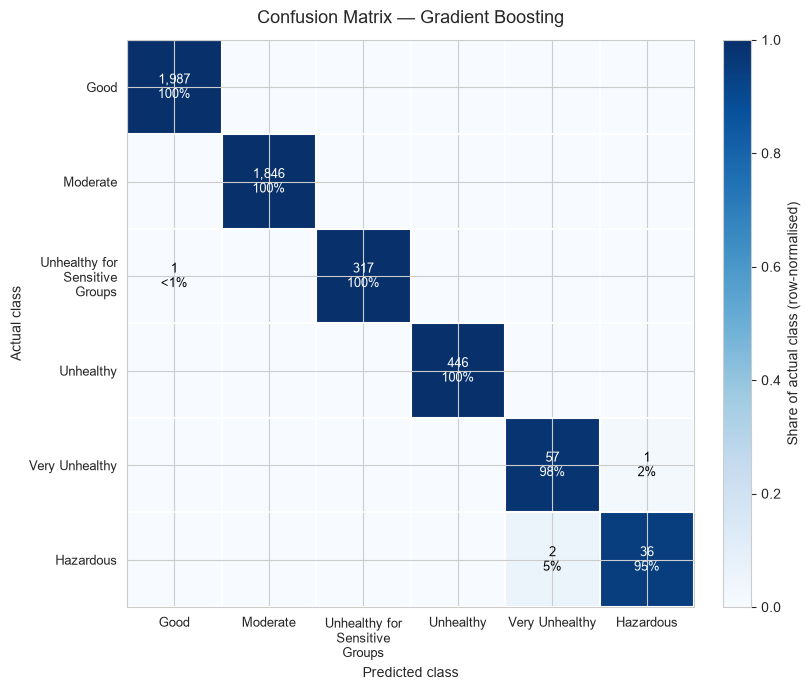

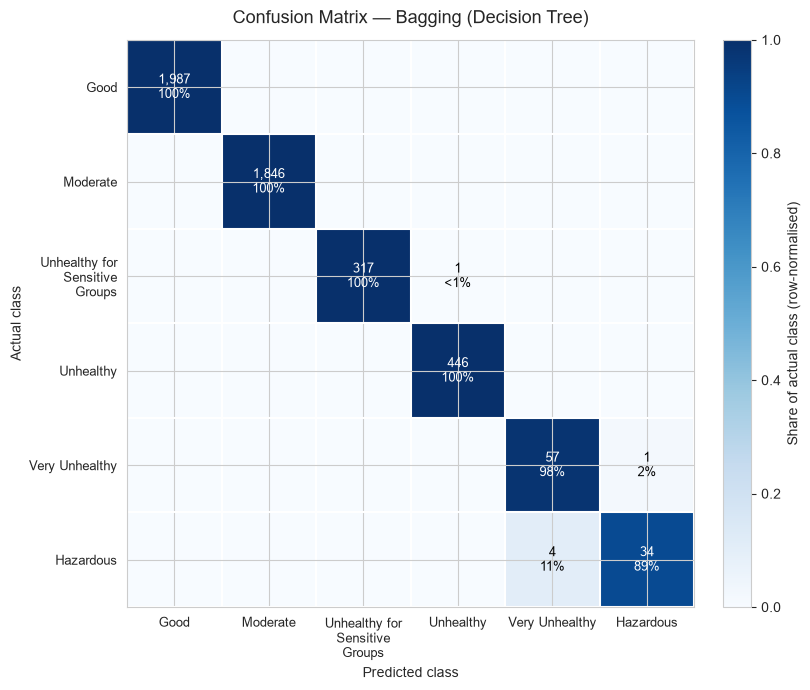

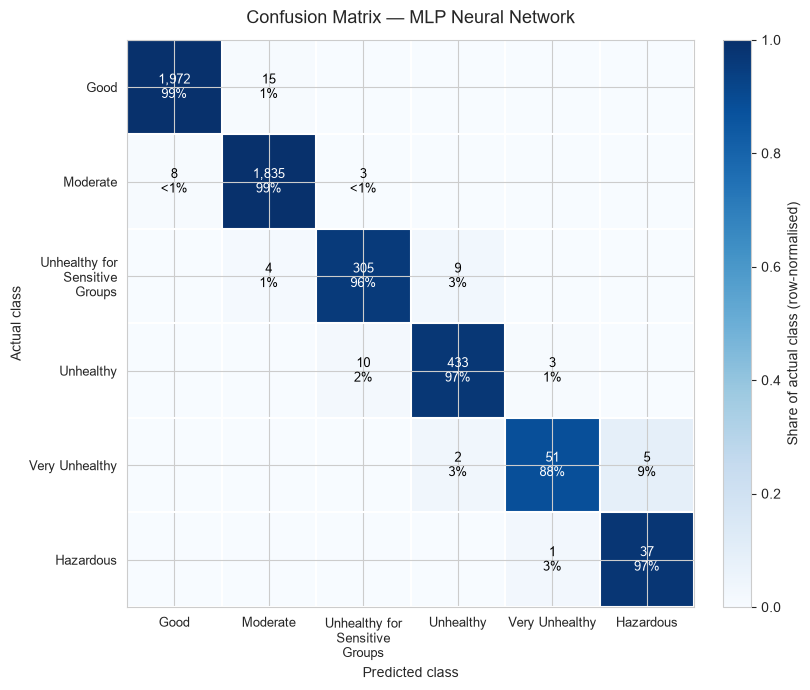

In [30]:
for name, pipeline in trained_part_b_models.items():
    plot_confusion_matrix(y_test_cls, pipeline.predict(X_test_cls), f"Confusion Matrix — {name}")

### Observation — Part B Confusion Matrices

The Part B confusion-matrix plots should be interpreted alongside the current classification results. The separate final tuned-model report shows very strong performance on `Good`, `Moderate`, `Unhealthy`, and `Unhealthy for Sensitive Groups` (each rounds to **1.00** for precision, recall, and F1-score). The minority classes are more difficult: `Hazardous` has **0.84 recall** and **0.89 F1-score**, while `Very Unhealthy` has **0.97 recall** and **0.93 F1-score**. These results differ from the earlier observation, which described much weaker minority-class recall; use the current report values instead.

## 22. Random Forest Feature Importance

Feature importance is extracted from the fitted Random Forest. The preprocessing pipeline is used to recover transformed feature names, including one-hot encoded categorical features when present.

,Feature,Importance
0,num__pm2.5_aqi_value,0.485307
1,num__average_pollutant_aqi,0.285183
2,num__ozone_aqi_value,0.069408
3,num__co_aqi_value,0.058880
4,num__no2_aqi_value,0.022997
5,cat__country_name_India,0.022271
6,cat__country_name_Pakistan,0.006921
7,cat__country_name_Russian Federation,0.004639
8,cat__country_name_United States of America,0.004370
9,cat__country_name_China,0.004077


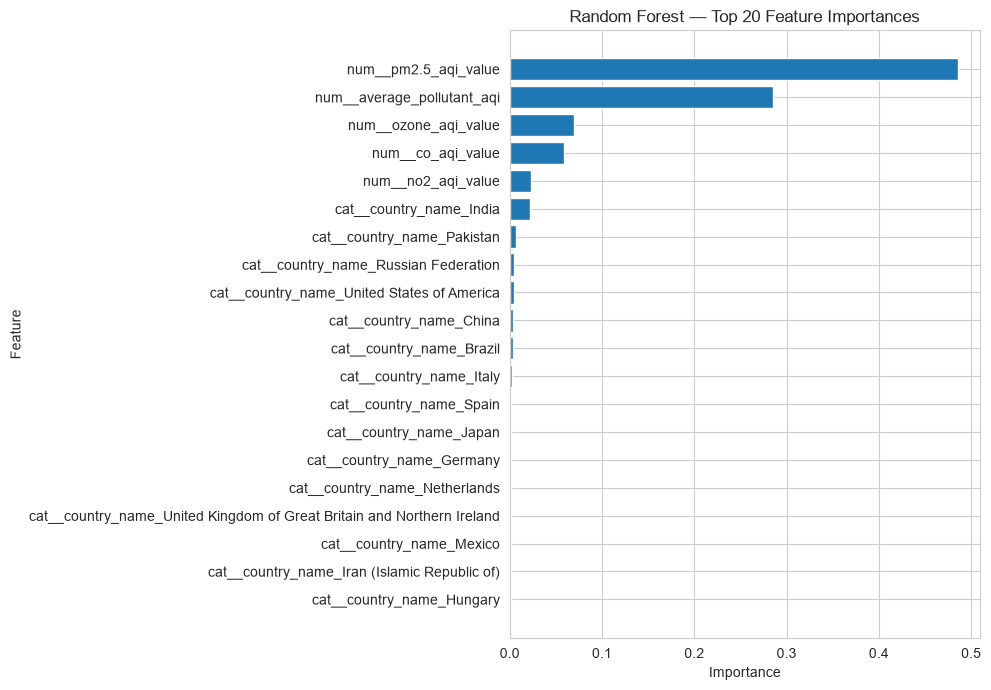

In [31]:
rf_pipeline = trained_part_b_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
preprocessor_fitted = rf_pipeline.named_steps["preprocessor"]

try:
    transformed_feature_names = preprocessor_fitted.get_feature_names_out()
except (AttributeError, ValueError):
    transformed_feature_names = np.array([
        f"feature_{i}" for i in range(len(rf_model.feature_importances_))
    ])

feature_importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(feature_importance_df.head(20))

top_features = feature_importance_df.head(20).sort_values("Importance")
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Random Forest — Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 23. Compare All Ten Classification Algorithms

The Review 2 guideline requires one consolidated table containing all five Part-A and all five Part-B algorithms, evaluated with Accuracy, Precision, Recall, weighted F1, and ROC-AUC. The table below merges the existing Part-A results with Part-B results.

In [32]:
# Recalculate Part-A ROC-AUC if the earlier result table was created before the helper was added.
part_a_complete_rows = []
for name, pipeline in trained_classification_models.items():
    pred = pipeline.predict(X_test_cls)
    part_a_complete_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_cls, pred),
        "Precision": precision_score(y_test_cls, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_cls, pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test_cls, pred, average="weighted", zero_division=0),
        "ROC-AUC (OvR)": calculate_roc_auc(pipeline, X_test_cls, y_test_cls)
    })

part_a_complete_df = pd.DataFrame(part_a_complete_rows)
all_classification_results_df = pd.concat(
    [part_a_complete_df, part_b_results_df],
    ignore_index=True
).sort_values("F1 Score", ascending=False).reset_index(drop=True)

display(all_classification_results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}",
    "ROC-AUC (OvR)": "{:.4f}"
}))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC (OvR)
0,Decision Tree,0.9994,0.9994,0.9994,0.9994,0.9997
1,Gradient Boosting,0.9991,0.9991,0.9991,0.9991,1.0000
2,Bagging (Decision Tree),0.9987,0.9987,0.9987,0.9987,1.0000
3,Random Forest,0.9968,0.9968,0.9968,0.9968,1.0000
4,MLP Neural Network,0.9872,0.9873,0.9872,0.9872,0.9995
5,SVM,0.9674,0.9681,0.9674,0.9672,0.9938
6,Logistic Regression,0.9478,0.9480,0.9478,0.9473,0.9939
7,KNN,0.9384,0.9381,0.9384,0.9379,0.9898
8,AdaBoost,0.9220,0.9010,0.9220,0.8992,0.9944
9,Naive Bayes,0.1890,0.5709,0.1890,0.2395,0.6277


### Observation — All Ten Models

The current Part A and Part B outputs show **Gradient Boosting** as the strongest model by held-out test accuracy and weighted F1 (**0.999148 accuracy; 0.999146 weighted F1**). Decision Tree is close behind (**0.999361 accuracy; 0.999361 weighted F1** in the Part A results), followed by Bagging (**0.998722 accuracy; 0.998713 weighted F1**) and Random Forest (**0.996804 accuracy; 0.996781 weighted F1**). MLP achieves **0.987215 accuracy / 0.987213 weighted F1**, while SVM, Logistic Regression, KNN, and AdaBoost perform below these leading models. Naive Bayes has the lowest weighted F1 in the current results (**0.239451 in Part A; 0.257865 mean cross-validation weighted F1**). The cross-validation table selects **Gradient Boosting**, with mean CV weighted F1 **0.999305** and standard deviation **0.000274**. The final tuned-model report still shows weaker performance for the less frequent `Hazardous` category than for the major classes.

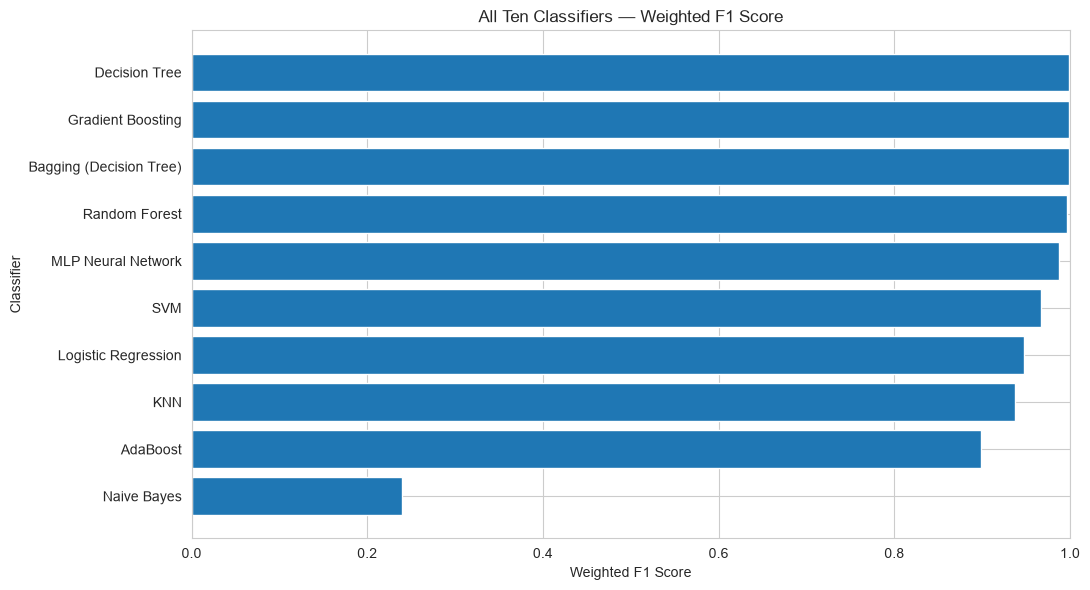

In [33]:
plt.figure(figsize=(11, 6))
plot_df = all_classification_results_df.sort_values("F1 Score")
plt.barh(plot_df["Model"], plot_df["F1 Score"])
plt.title("All Ten Classifiers — Weighted F1 Score")
plt.xlabel("Weighted F1 Score")
plt.ylabel("Classifier")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# Observation — All Ten Models F1 Chart

The current results place **Gradient Boosting** at a weighted F1 of **0.999146**, **Decision Tree** at **0.999361**, **Bagging** at **0.998713**, and **Random Forest** at **0.996781**. MLP follows at **0.987213**, while AdaBoost records **0.899209**. Naive Bayes is substantially lower, with weighted F1 **0.239451** in the Part A test results. The strongest models are close to one another, so weighted F1 should be considered together with cross-validation and class-wise recall rather than used alone.

## 24. Select and Tune the Best Model

The best model is selected using mean weighted F1 from cross-validation on the training set. GridSearchCV then tests parameter combinations for that model. The held-out test set is used to compare performance before and after tuning.

In [34]:
# Select the winner using cross-validation on training data, not test-set scores.
all_trained_models = {**trained_classification_models, **trained_part_b_models}
cv_rows = []

for name, pipeline in all_trained_models.items():
    scores = cross_val_score(
        pipeline,
        X_train_cls,
        y_train_cls,
        cv=3,
        scoring="f1_weighted",
        n_jobs=1
    )
    cv_rows.append({
        "Model": name,
        "Mean CV weighted F1": scores.mean(),
        "CV standard deviation": scores.std()
    })

cv_comparison_df = pd.DataFrame(cv_rows).sort_values(
    "Mean CV weighted F1", ascending=False
).reset_index(drop=True)
display(cv_comparison_df)

best_initial_name = cv_comparison_df.iloc[0]["Model"]
best_initial_pipeline = all_trained_models[best_initial_name]
best_estimator = best_initial_pipeline.named_steps["model"]

before_predictions = best_initial_pipeline.predict(X_test_cls)
before_metrics = {
    "Accuracy": accuracy_score(y_test_cls, before_predictions),
    "Precision": precision_score(y_test_cls, before_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y_test_cls, before_predictions, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test_cls, before_predictions, average="weighted", zero_division=0),
    "ROC-AUC (OvR)": calculate_roc_auc(best_initial_pipeline, X_test_cls, y_test_cls)
}

print("Model selected by training-set cross-validation:", best_initial_name)
print("Held-out test metrics before final tuning:")
display(pd.DataFrame([before_metrics]))

,Model,Mean CV weighted F1,CV standard deviation
0,Gradient Boosting,0.999305,0.000274
1,Decision Tree,0.999147,0.000273
2,Bagging (Decision Tree),0.999143,0.000403
3,Random Forest,0.994842,0.000205
4,MLP Neural Network,0.983587,0.001394
5,SVM,0.960392,0.002431
6,Logistic Regression,0.937640,0.000944
7,AdaBoost,0.926044,0.023451
8,KNN,0.923928,0.002841
9,Naive Bayes,0.257865,0.008461


Model selected by training-set cross-validation: Gradient Boosting
Held-out test metrics before final tuning:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC (OvR)
0,0.999148,0.999149,0.999148,0.999146,0.999999


### Grid search configuration

The parameter grid is selected for the chosen estimator. If the best initial model is one of the Part-A models, its corresponding grid is used as well.

In [ ]:
# A final, slightly broader grid is applied to the model selected by training CV.
final_param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"]
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9],
        "model__weights": ["uniform", "distance"]
    },
    "Naive Bayes": {
        "model__var_smoothing": [1e-9, 1e-8, 1e-7]
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10]
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["rbf", "linear"]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    },
    "AdaBoost": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1, 1.0]
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 150],
        "model__learning_rate": [0.03, 0.1, 0.2],
        "model__max_depth": [2, 3]
    },
    "Bagging (Decision Tree)": {
        "model__n_estimators": [50, 100, 200],
        "model__max_samples": [0.7, 1.0]
    },
    "MLP Neural Network": {
        "model__hidden_layer_sizes": [(50,), (100,), (100, 50)],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [0.0001, 0.001]
    }
}

tuning_pipeline = Pipeline(steps=[
    ("preprocessor", classification_preprocessor),
    ("model", best_estimator)
])

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=final_param_grids[best_initial_name],
    scoring="f1_weighted",
    cv=3,
    n_jobs=1,
    verbose=1,
    refit=True
)
grid_search.fit(X_train_cls, y_train_cls)

tuned_best_model = grid_search.best_estimator_
tuned_predictions = tuned_best_model.predict(X_test_cls)

after_metrics = {
    "Accuracy": accuracy_score(y_test_cls, tuned_predictions),
    "Precision": precision_score(y_test_cls, tuned_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y_test_cls, tuned_predictions, average="weighted", zero_division=0),
    "F1 Score": f1_score(y_test_cls, tuned_predictions, average="weighted", zero_division=0),
    "ROC-AUC (OvR)": calculate_roc_auc(tuned_best_model, X_test_cls, y_test_cls)
}

tuning_comparison_df = pd.DataFrame([
    {"Stage": "Before final tuning", "Model": best_initial_name, **before_metrics},
    {"Stage": "After final tuning", "Model": best_initial_name + " (tuned)", **after_metrics}
])

print("Best parameters from final GridSearchCV:")
print(grid_search.best_params_)
print(f"Best mean CV weighted F1: {grid_search.best_score_:.4f}")
display(tuning_comparison_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1 Score": "{:.4f}", "ROC-AUC (OvR)": "{:.4f}"
}))

Fitting 3 folds for each of 12 candidates, totalling 36 fits


### Tuning Observation

The current cross-validation results select **Gradient Boosting** because it has the highest mean CV weighted F1 (**0.999305**, standard deviation **0.000274**). Before the final grid search, its held-out test metrics were **0.999148 accuracy**, **0.999149 precision**, **0.999148 recall**, **0.999146 weighted F1**, and **0.999999 ROC-AUC (OvR)**. The grid-search cell output currently confirms that 3-fold cross-validation evaluated **12 parameter combinations (36 fits)**

## 25. Tuned Model Confusion Matrix and Classification Report

The tuned model is evaluated on the same held-out test set as the original models.

TUNED MODEL CLASSIFICATION REPORT
                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00      1987
                     Hazardous       0.94      0.84      0.89        38
                      Moderate       1.00      1.00      1.00      1846
                     Unhealthy       1.00      1.00      1.00       446
Unhealthy for Sensitive Groups       1.00      1.00      1.00       318
                Very Unhealthy       0.90      0.97      0.93        58

                      accuracy                           1.00      4693
                     macro avg       0.97      0.97      0.97      4693
                  weighted avg       1.00      1.00      1.00      4693



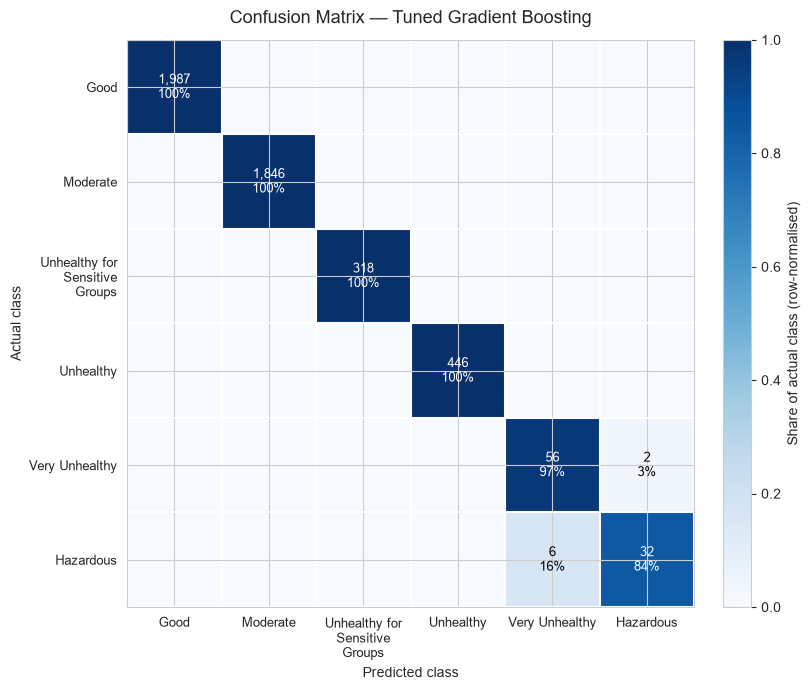

In [36]:
print("TUNED MODEL CLASSIFICATION REPORT")
print(classification_report(y_test_cls, tuned_predictions, zero_division=0))

tuned_cm, tuned_classes = plot_confusion_matrix(
    y_test_cls, tuned_predictions, f"Confusion Matrix — Tuned {best_initial_name}")

## 26. Review 2 Conclusion — Classification

This experiment compares ten classification algorithms for the six AQI categories using the saved train/test split. In the current outputs, **Decision Tree** records the highest Part A test accuracy and weighted F1 (**0.999361** for both), while **Gradient Boosting** leads the Part B models (**0.999148 accuracy; 0.999146 weighted F1**) and has the highest mean cross-validation weighted F1 across the ten models (**0.999305**, standard deviation **0.000274**). Based on cross-validation, Gradient Boosting is selected for the final tuning stage. Its pre-tuning held-out test metrics are **0.999148 accuracy**, **0.999149 precision**, **0.999148 recall**, **0.999146 weighted F1**, and **0.999999 ROC-AUC (OvR)**.

The final tuned-model classification report shows near-perfect results for `Good`, `Moderate`, `Unhealthy`, and `Unhealthy for Sensitive Groups` (metrics round to **1.00**). `Hazardous` is the main remaining challenge, with **0.84 recall** and **0.89 F1-score**; `Very Unhealthy` has **0.97 recall** and **0.93 F1-score**. 